In [1]:
import torch

if torch.cuda.is_available():
    print("GPU is available!")
    print(torch.cuda.get_device_name(0))
else:
    print("GPU is not available!")

GPU is available!
NVIDIA GeForce RTX 3060 Laptop GPU


# Transfer Learning and Fine-Tuning with ParsBERT

## Objective
In this notebook, we fine-tune a pretrained Persian BERT model (ParsBERT)
for multi-task classification of Digikala product reviews.

The model has two classification heads:

1. Recommendation Status Classification
2. Rating Band Classification

## Main Steps
1. Load and inspect the datasets.
2. Clean and prepare labels.
3. Load the pretrained tokenizer.
4. Build a custom PyTorch Dataset and DataLoader.
5. Build a shared ParsBERT encoder with two classification heads.
6. Fine-tune the model.
7. Evaluate the model on the validation dataset.
8. Select the best checkpoint.
9. Evaluate the selected model on the test dataset.

The test dataset contains agent-generated reviews and labels.

In [33]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

### Configuration

In [9]:
# Dataset paths
# DATA_DIR = Path("../data")

from pathlib import Path

DATA_DIR = Path("../data")

TRAIN_PATH = DATA_DIR / "train_experiment_500k.csv"
VALIDATION_PATH = DATA_DIR / "validation_50k_corrected.csv"
TEST_PATH = DATA_DIR / "test.csv"
REAL_TEST_PATH = DATA_DIR / "test_10k_corrected.csv"

# Pretrained model
MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"

# Dataset columns
ID_COL = "id"
PRODUCT_COL = "product_id"
TEXT_COL = "text"
RATING_COL = "rate"

RECOMMENDATION_COL = "recommendation_status"
RATING_BAND_COL = "rating_band"

# Classification labels
RECOMMENDATION_LABELS = [
    "recommended",
    "not_recommended",
    "no_idea"
]

RATING_LABELS = [
    "low",
    "medium",
    "high"
]

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Model:", MODEL_NAME)

Device: cpu
Model: HooshvareLab/bert-fa-base-uncased


In [10]:
print("Train:", TRAIN_PATH.exists())
print("Validation:", VALIDATION_PATH.exists())
print("Test:", TEST_PATH.exists())

Train: True
Validation: True
Test: True


### Loading Datasets

In [11]:
# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

# Display dataset shapes
print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

# Display available columns
print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

Train shape: (500000, 5)
Validation shape: (50000, 5)
Test shape: (10000, 4)

Train columns:
['id', 'product_id', 'text', 'recommendation_status', 'rate']

Validation columns:
['id', 'product_id', 'text', 'recommendation_status', 'rate']

Test columns:
['id', 'text', 'recommendation_status', 'rate']


In [37]:
def standardize_columns(df):
    df = df.copy()

    # Rename body to text if necessary
    if TEXT_COL not in df.columns and "body" in df.columns:
        df = df.rename(columns={"body": TEXT_COL})

    return df


train_df = standardize_columns(train_df)
validation_df = standardize_columns(validation_df)
test_df = standardize_columns(test_df)

### Checking Required Columns

In [12]:
# Define required columns for each dataset
required_columns = [
    ID_COL,
    TEXT_COL,
    RECOMMENDATION_COL
]

# Check required columns
for name, df in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{name} is missing columns: {missing_columns}"
        )

print("All required columns are available.")

All required columns are available.


In [13]:
def prepare_dataframe(df, dataset_name):
    df = df.copy()

    # Clean review text
    df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str).str.strip()

    # Normalize recommendation labels
    df[RECOMMENDATION_COL] = (
        df[RECOMMENDATION_COL]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Convert rating values to numeric
    if RATING_COL in df.columns:
        df[RATING_COL] = pd.to_numeric(
            df[RATING_COL],
            errors="coerce"
        )

        # Create rating bands
        df[RATING_BAND_COL] = pd.cut(
            df[RATING_COL],
            bins=[-np.inf, 2.5, 4, np.inf],
            labels=RATING_LABELS,
            right=False
        )

    print(f"{dataset_name} prepared: {df.shape}")

    return df


train_df = prepare_dataframe(train_df, "Train")
validation_df = prepare_dataframe(validation_df, "Validation")
test_df = prepare_dataframe(test_df, "Test")

Train prepared: (500000, 6)
Validation prepared: (50000, 6)
Test prepared: (10000, 5)


### Reviewing tags and empty data

In [14]:
# Define valid labels
valid_recommendation_labels = set(RECOMMENDATION_LABELS)
valid_rating_labels = set(RATING_LABELS)


def inspect_labels(df, dataset_name):

    print(f"\n{'=' * 40}")
    print(dataset_name)
    print(f"{'=' * 40}")

    # Check recommendation labels
    recommendation_values = set(
        df[RECOMMENDATION_COL].dropna().unique()
    ) - {""}

    print("\nRecommendation labels:")
    print(recommendation_values)

    invalid_recommendation = (
        recommendation_values - valid_recommendation_labels
    )

    # Check rating labels
    rating_values = set(
        df[RATING_BAND_COL].dropna().astype(str).unique()
    ) - {""}

    print("\nRating labels:")
    print(rating_values)

    invalid_rating = rating_values - valid_rating_labels

    # Display invalid labels
    print("\nInvalid recommendation labels:", invalid_recommendation)
    print("Invalid rating labels:", invalid_rating)

    # Check missing values
    print("\nMissing recommendation labels:",
          (df[RECOMMENDATION_COL] == "").sum())

    print("Missing rating labels:",
          df[RATING_BAND_COL].isna().sum()
          + (df[RATING_BAND_COL].astype(str) == "").sum())

    print("Empty texts:", (df[TEXT_COL] == "").sum())


for name, df in [
    ("Train", train_df),
    ("Validation", validation_df),
    # ("Test", test_df)
]:
    inspect_labels(df, name)


Train

Recommendation labels:
{'no_idea', 'recommended', 'not_recommended'}

Rating labels:
{'medium', 'low', 'high'}

Invalid recommendation labels: set()
Invalid rating labels: set()

Missing recommendation labels: 0
Missing rating labels: 0
Empty texts: 0

Validation

Recommendation labels:
{'no_idea', 'recommended', 'not_recommended'}

Rating labels:
{'medium', 'low', 'high'}

Invalid recommendation labels: set()
Invalid rating labels: set()

Missing recommendation labels: 0
Missing rating labels: 0
Empty texts: 0


In [15]:
# Create label-to-ID mappings
recommendation_to_id = {
    label: index
    for index, label in enumerate(RECOMMENDATION_LABELS)
}

rating_to_id = {
    label: index
    for index, label in enumerate(RATING_LABELS)
}

# Display mappings
print("Recommendation mapping:")
print(recommendation_to_id)

print("\nRating mapping:")
print(rating_to_id)

Recommendation mapping:
{'recommended': 0, 'not_recommended': 1, 'no_idea': 2}

Rating mapping:
{'low': 0, 'medium': 1, 'high': 2}


### Loading the Pretrained Tokenizer

In this section, we load the tokenizer associated with ParsBERT.

The tokenizer converts Persian review texts into token IDs that can be processed by the BERT model.

We also inspect the tokenized review lengths to choose an appropriate maximum sequence length.

In [16]:
# Load the pretrained tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Define the maximum sequence length
MAX_LENGTH = 128

# Display tokenizer information
print("Tokenizer loaded successfully.")
print("Tokenizer:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model length:", tokenizer.model_max_length)
print("Selected maximum sequence length:", MAX_LENGTH)

Tokenizer loaded successfully.
Tokenizer: HooshvareLab/bert-fa-base-uncased
Vocabulary size: 100000
Maximum model length: 1000000000000000019884624838656
Selected maximum sequence length: 128


In [17]:
# Sample reviews for token length analysis
sample_size = min(10000, len(train_df))

sample_texts = train_df[TEXT_COL].sample(
    n=sample_size,
    random_state=SEED
).tolist()

# Tokenize sampled reviews without truncation
sample_tokens = tokenizer(
    sample_texts,
    add_special_tokens=True,
    truncation=False
)

# Calculate token lengths
token_lengths = [
    len(token_ids)
    for token_ids in sample_tokens["input_ids"]
]

# Display token length statistics
print("Token length statistics:")
print(pd.Series(token_lengths).describe())

# Calculate the percentage of reviews longer than MAX_LENGTH
long_reviews = sum(
    length > MAX_LENGTH
    for length in token_lengths
)

long_percentage = (long_reviews / sample_size) * 100

print(f"\nReviews longer than {MAX_LENGTH} tokens: {long_reviews:,}")
print(f"Percentage of long reviews: {long_percentage:.2f}%")

Token length statistics:
count    10000.000000
mean        16.270800
std         15.125606
min          3.000000
25%          8.000000
50%         12.000000
75%         19.000000
max        317.000000
dtype: float64

Reviews longer than 128 tokens: 16
Percentage of long reviews: 0.16%


### Visualizing Token Length Distribution

In this section, we visualize the distribution of token lengths in the sampled reviews.

This helps us understand how review lengths are distributed and whether the selected maximum sequence length is appropriate.

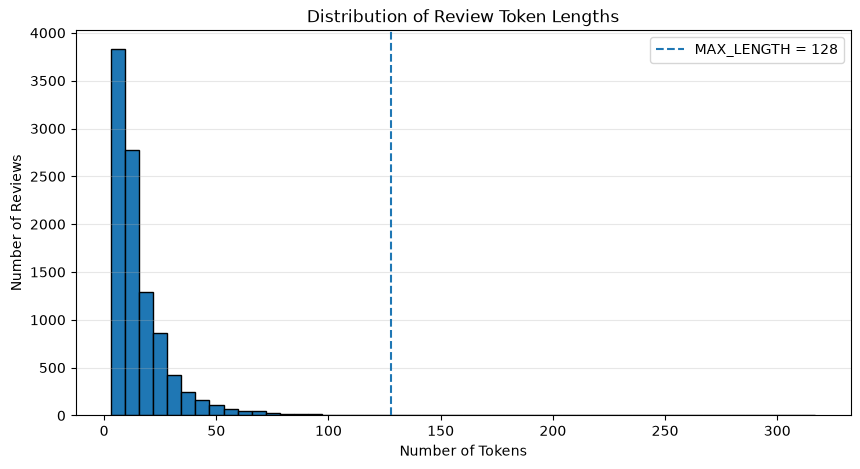

In [12]:
import matplotlib.pyplot as plt

# Plot token length distribution
plt.figure(figsize=(10, 5))

plt.hist(
    token_lengths,
    bins=50,
    edgecolor="black"
)

plt.axvline(
    MAX_LENGTH,
    linestyle="--",
    label=f"MAX_LENGTH = {MAX_LENGTH}"
)

plt.title("Distribution of Review Token Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Reviews")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [18]:
# Define valid labels
valid_recommendation_labels = set(RECOMMENDATION_LABELS)
valid_rating_labels = set(RATING_LABELS)


def inspect_labels(df, dataset_name):

    print(f"\n{'=' * 40}")
    print(dataset_name)
    print(f"{'=' * 40}")

    # Check recommendation labels
    recommendation_values = set(
        df[RECOMMENDATION_COL].dropna().unique()
    ) - {""}

    print("\nRecommendation labels:")
    print(recommendation_values)

    invalid_recommendation = (
        recommendation_values - valid_recommendation_labels
    )

    # Check rating labels
    rating_values = set(
        df[RATING_BAND_COL].dropna().astype(str).unique()
    ) - {""}

    print("\nRating labels:")
    print(rating_values)

    invalid_rating = rating_values - valid_rating_labels

    # Display invalid labels
    print("\nInvalid recommendation labels:", invalid_recommendation)
    print("Invalid rating labels:", invalid_rating)

    # Check missing values
    print("\nMissing recommendation labels:",
          (df[RECOMMENDATION_COL] == "").sum())

    print("Missing rating labels:",
          df[RATING_BAND_COL].isna().sum()
          + (df[RATING_BAND_COL].astype(str) == "").sum())

    print("Empty texts:", (df[TEXT_COL] == "").sum())


for name, df in [
    ("Train", train_df),
    ("Validation", validation_df),
    # ("Test", test_df)
]:
    inspect_labels(df, name)


Train

Recommendation labels:
{'no_idea', 'recommended', 'not_recommended'}

Rating labels:
{'medium', 'low', 'high'}

Invalid recommendation labels: set()
Invalid rating labels: set()

Missing recommendation labels: 0
Missing rating labels: 0
Empty texts: 0

Validation

Recommendation labels:
{'no_idea', 'recommended', 'not_recommended'}

Rating labels:
{'medium', 'low', 'high'}

Invalid recommendation labels: set()
Invalid rating labels: set()

Missing recommendation labels: 0
Missing rating labels: 0
Empty texts: 0


### Creating a Custom PyTorch Dataset

In this section, we create a custom PyTorch Dataset for multi-task classification.

Each sample contains:
- Review text
- Recommendation label
- Rating band label

Missing labels are represented by -100 so that each classification task can calculate its loss independently.

Tokenization will be performed later in batches to reduce memory usage.

In [19]:
class ReviewDataset(Dataset):

    def __init__(self, dataframe):
        self.texts = dataframe[TEXT_COL].tolist()

        # Convert recommendation labels to numerical IDs
        self.recommendation_labels = [
            recommendation_to_id.get(label, -100)
            for label in dataframe[RECOMMENDATION_COL]
        ]

        # Convert rating labels to numerical IDs
        if RATING_BAND_COL in dataframe.columns:
            rating_values = dataframe[RATING_BAND_COL].astype("string").tolist()

            self.rating_labels = [
                rating_to_id.get(label, -100)
                if pd.notna(label) else -100
                for label in rating_values
            ]
        else:
            self.rating_labels = [-100] * len(dataframe)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        return {
            "text": self.texts[index],
            "recommendation_label": self.recommendation_labels[index],
            "rating_label": self.rating_labels[index]
        }

In [20]:
# Create PyTorch datasets
train_dataset = ReviewDataset(train_df)
validation_dataset = ReviewDataset(validation_df)
test_dataset = ReviewDataset(test_df)

# Display dataset sizes
print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(validation_dataset))
print("Test dataset size:", len(test_dataset))

# Inspect one sample
print("\nFirst training sample:")
print(train_dataset[0])

Train dataset size: 500000
Validation dataset size: 50000
Test dataset size: 10000

First training sample:
{'text': 'کامل و خوب با دوبار بدقولی', 'recommendation_label': 0, 'rating_label': 2}


### Creating DataLoaders

In this section, we create DataLoaders to feed data into the model in batches.

Instead of processing the entire dataset at once, DataLoader loads a small batch of samples at each iteration.

We also use dynamic padding to reduce unnecessary padding tokens and improve memory efficiency.

In [21]:
from torch.utils.data import DataLoader


# Define batch size
BATCH_SIZE = 8

# Define a custom collate function
def collate_fn(batch):

    # Extract review texts
    texts = [item["text"] for item in batch]

    # Tokenize the batch
    encodings = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_attention_mask=True,
        return_tensors="pt"
    )

    # Convert labels to PyTorch tensors
    recommendation_labels = torch.tensor(
        [item["recommendation_label"] for item in batch],
        dtype=torch.long
    )

    rating_labels = torch.tensor(
        [item["rating_label"] for item in batch],
        dtype=torch.long
    )

    # Return model inputs and labels
    return {
        "input_ids": encodings["input_ids"],
        "attention_mask": encodings["attention_mask"],
        "recommendation_labels": recommendation_labels,
        "rating_labels": rating_labels
    }


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("DataLoaders created successfully.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully.
Train batches: 62500
Validation batches: 6250
Test batches: 1250


### Inspecting a DataLoader Batch

In this section, we inspect the first training batch to verify the input tensor shapes, data types, and label values.

In [18]:
# Get one batch from the training DataLoader
sample_batch = next(iter(train_loader))

# Display tensor shapes
print("Input IDs shape:", sample_batch["input_ids"].shape)
print("Attention Mask shape:", sample_batch["attention_mask"].shape)

print("\nRecommendation labels shape:",
      sample_batch["recommendation_labels"].shape)

print("Rating labels shape:",
      sample_batch["rating_labels"].shape)

# Display tensor data types
print("\nInput IDs dtype:", sample_batch["input_ids"].dtype)
print("Recommendation labels dtype:",
      sample_batch["recommendation_labels"].dtype)

# Display label values
print("\nRecommendation labels:",
      sample_batch["recommendation_labels"])

print("Rating labels:",
      sample_batch["rating_labels"])

Input IDs shape: torch.Size([8, 15])
Attention Mask shape: torch.Size([8, 15])

Recommendation labels shape: torch.Size([8])
Rating labels shape: torch.Size([8])

Input IDs dtype: torch.int64
Recommendation labels dtype: torch.int64

Recommendation labels: tensor([2, 1, 0, 2, 1, 1, 1, 0])
Rating labels: tensor([1, 0, 2, 1, 0, 0, 0, 2])


### Building the Multi-Task ParsBERT Model

In this section, we load the pretrained ParsBERT encoder and build a multi-task classification architecture.

The model consists of:

1. A shared pretrained ParsBERT encoder.
2. A dropout layer to reduce overfitting.
3. A recommendation classification head with 3 output classes.
4. A rating classification head with 3 output classes.

Both classification heads use the same text representations extracted by the shared encoder.

In [22]:
# Define the multi-task classification model
class MultiTaskParsBERT(nn.Module):

    def __init__(self, model_name, num_recommendation_classes, num_rating_classes, dropout_rate=0.3):
        super().__init__()

        # Load the pretrained ParsBERT encoder
        self.encoder = AutoModel.from_pretrained(model_name)

        # Get the encoder hidden size
        hidden_size = self.encoder.config.hidden_size

        # Shared dropout layer
        self.dropout = nn.Dropout(dropout_rate)

        # Recommendation classification head
        self.recommendation_classifier = nn.Linear(
            hidden_size,
            num_recommendation_classes
        )

        # Rating classification head
        self.rating_classifier = nn.Linear(
            hidden_size,
            num_rating_classes
        )

    def forward(self, input_ids, attention_mask):

        # Extract contextual representations from ParsBERT
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Use the representation of the [CLS] token
        pooled_output = outputs.last_hidden_state[:, 0, :]

        # Apply dropout
        pooled_output = self.dropout(pooled_output)

        # Generate predictions for both tasks
        recommendation_logits = self.recommendation_classifier(
            pooled_output
        )

        rating_logits = self.rating_classifier(
            pooled_output
        )

        return {
            "recommendation_logits": recommendation_logits,
            "rating_logits": rating_logits
        }

### Initializing the Model

In this section, we initialize the multi-task ParsBERT model and move it to the selected device.

We also calculate the total number of parameters and the number of trainable parameters.

In [23]:
# Initialize the multi-task model
model = MultiTaskParsBERT(
    model_name=MODEL_NAME,
    num_recommendation_classes=len(RECOMMENDATION_LABELS),
    num_rating_classes=len(RATING_LABELS),
    dropout_rate=0.3
)

# Move the model to the selected device
model = model.to(DEVICE)


# Count model parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)


print("Model initialized successfully.")
print("Device:", DEVICE)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13087.26it/s]
[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model initialized successfully.
Device: cpu
Total parameters: 162,845,958
Trainable parameters: 162,845,958


### Testing the Model Forward Pass

In this section, we pass one batch of data through the model without updating its parameters.

We verify that both classification heads produce the expected output shapes.

In [21]:
# Get one batch from the training DataLoader
sample_batch = next(iter(train_loader))

# Move input tensors to the selected device
input_ids = sample_batch["input_ids"].to(DEVICE)
attention_mask = sample_batch["attention_mask"].to(DEVICE)


# Run a forward pass without calculating gradients
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )


# Display output shapes
print(
    "Recommendation logits shape:",
    outputs["recommendation_logits"].shape
)

print(
    "Rating logits shape:",
    outputs["rating_logits"].shape
)

# Display raw predictions
print("\nRecommendation logits:")
print(outputs["recommendation_logits"])

print("\nRating logits:")
print(outputs["rating_logits"])

Recommendation logits shape: torch.Size([8, 3])
Rating logits shape: torch.Size([8, 3])

Recommendation logits:
tensor([[ 0.4738,  0.0264,  0.4574],
        [ 0.1102, -0.2718,  0.0343],
        [-0.0366, -0.2832, -0.1841],
        [-0.3839, -0.1510, -0.5760],
        [ 0.0881, -0.7866, -0.1091],
        [ 0.1497, -0.5361, -0.2503],
        [ 0.4506, -0.8541,  0.0901],
        [-0.0845, -0.4391, -0.0353]], device='cuda:0')

Rating logits:
tensor([[ 0.2029, -0.3185, -0.8541],
        [ 0.2033,  0.0266, -0.4966],
        [ 0.2128, -0.5584, -0.4408],
        [ 0.0675, -0.3379, -0.9344],
        [-0.3669, -0.7455, -0.3636],
        [ 0.2065, -0.1663, -0.4041],
        [-0.0680, -0.1302, -0.3656],
        [ 0.2692,  0.1104, -0.1764]], device='cuda:0')


### Defining the Multi-Task Loss Function

In this section, we define a separate Cross-Entropy Loss for each classification task.

The model learns two tasks simultaneously:
1. Recommendation Status Classification
2. Rating Band Classification

Missing labels are ignored independently for each task.

The final loss is calculated by averaging the available task losses.

In [24]:
# Define the loss function
criterion = nn.CrossEntropyLoss()


def compute_multitask_loss(outputs, recommendation_labels, rating_labels):

    # Calculate recommendation loss using valid labels only
    recommendation_mask = recommendation_labels != -100

    if recommendation_mask.any():
        recommendation_loss = criterion(
            outputs["recommendation_logits"][recommendation_mask],
            recommendation_labels[recommendation_mask]
        )
    else:
        recommendation_loss = None

    # Calculate rating loss using valid labels only
    rating_mask = rating_labels != -100

    if rating_mask.any():
        rating_loss = criterion(
            outputs["rating_logits"][rating_mask],
            rating_labels[rating_mask]
        )
    else:
        rating_loss = None

    # Combine available task losses
    available_losses = [
        loss for loss in [recommendation_loss, rating_loss]
        if loss is not None
    ]

    if not available_losses:
        return None, recommendation_loss, rating_loss

    total_loss = torch.stack(available_losses).mean()

    return total_loss, recommendation_loss, rating_loss

### Training Configuration

In this section, we define the main hyperparameters for fine-tuning.

We use gradient accumulation to simulate a larger effective batch size while keeping the actual batch size small.

We also define early stopping settings to prevent unnecessary training.

In [25]:
# Training hyperparameters
EPOCHS = 10

BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 4

ENCODER_LEARNING_RATE = 2e-5
HEAD_LEARNING_RATE = 1e-4

WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

MAX_GRAD_NORM = 1.0

EARLY_STOPPING_PATIENCE = 4

print("Training configuration:")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation steps:", GRADIENT_ACCUMULATION_STEPS)
print("Effective batch size:", BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Encoder learning rate:", ENCODER_LEARNING_RATE)
print("Head learning rate:", HEAD_LEARNING_RATE)

Training configuration:
Epochs: 10
Batch size: 8
Gradient accumulation steps: 4
Effective batch size: 32
Encoder learning rate: 2e-05
Head learning rate: 0.0001


### Initializing the Optimizer

In this section, we initialize the AdamW optimizer.

We use separate learning rates for the pretrained ParsBERT encoder and the newly added classification heads.

The encoder uses a smaller learning rate to preserve its pretrained knowledge, while the classification heads use a larger learning rate.

In [26]:
# Define optimizer parameter groups
optimizer_grouped_parameters = [
    {
        "params": model.encoder.parameters(),
        "lr": ENCODER_LEARNING_RATE
    },
    {
        "params": model.recommendation_classifier.parameters(),
        "lr": HEAD_LEARNING_RATE
    },
    {
        "params": model.rating_classifier.parameters(),
        "lr": HEAD_LEARNING_RATE
    }
]

# Initialize AdamW optimizer
optimizer = torch.optim.AdamW(
    optimizer_grouped_parameters,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer initialized successfully.")

Optimizer initialized successfully.


### Initializing the Learning Rate Scheduler

In this section, we create a linear learning rate scheduler with a warmup phase.

The learning rate gradually increases during the warmup steps and then decreases linearly throughout training.

In [27]:
import math

# Calculate the number of optimizer update steps per epoch
updates_per_epoch = math.ceil(
    len(train_loader) / GRADIENT_ACCUMULATION_STEPS
)

# Calculate the total number of training steps
total_training_steps = updates_per_epoch * EPOCHS

# Calculate the number of warmup steps
warmup_steps = int(total_training_steps * WARMUP_RATIO)

# Initialize the learning rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("Scheduler initialized successfully.")
print("Updates per epoch:", updates_per_epoch)
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

Scheduler initialized successfully.
Updates per epoch: 15625
Total training steps: 156250
Warmup steps: 15625


In [28]:
def evaluate_model(model, data_loader):
    model.eval()

    total_loss = 0
    total_batches = 0

    all_recommendation_labels = []
    all_recommendation_predictions = []

    all_rating_labels = []
    all_rating_predictions = []

    with torch.no_grad():

        for batch in tqdm(data_loader, desc="Evaluating"):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            recommendation_labels = batch["recommendation_labels"].to(DEVICE)
            rating_labels = batch["rating_labels"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss, recommendation_loss, rating_loss = compute_multitask_loss(
                outputs,
                recommendation_labels,
                rating_labels
            )

            if loss is not None:
                total_loss += loss.item()
                total_batches += 1

            # Recommendation predictions
            recommendation_mask = recommendation_labels != -100

            if recommendation_mask.any():
                recommendation_predictions = torch.argmax(
                    outputs["recommendation_logits"][recommendation_mask],
                    dim=1
                )

                all_recommendation_labels.extend(
                    recommendation_labels[recommendation_mask].cpu().tolist()
                )

                all_recommendation_predictions.extend(
                    recommendation_predictions.cpu().tolist()
                )

            # Rating predictions
            rating_mask = rating_labels != -100

            if rating_mask.any():
                rating_predictions = torch.argmax(
                    outputs["rating_logits"][rating_mask],
                    dim=1
                )

                all_rating_labels.extend(
                    rating_labels[rating_mask].cpu().tolist()
                )

                all_rating_predictions.extend(
                    rating_predictions.cpu().tolist()
                )

    # Calculate validation loss
    average_loss = total_loss / total_batches if total_batches > 0 else 0

    # Calculate recommendation metrics
    recommendation_accuracy = accuracy_score(
        all_recommendation_labels,
        all_recommendation_predictions
    )

    recommendation_macro_f1 = f1_score(
        all_recommendation_labels,
        all_recommendation_predictions,
        average="macro"
    )

    # Calculate rating metrics
    rating_accuracy = accuracy_score(
        all_rating_labels,
        all_rating_predictions
    )

    rating_macro_f1 = f1_score(
        all_rating_labels,
        all_rating_predictions,
        average="macro"
    )

    return {
        "loss": average_loss,
        "recommendation_accuracy": recommendation_accuracy,
        "recommendation_macro_f1": recommendation_macro_f1,
        "rating_accuracy": rating_accuracy,
        "rating_macro_f1": rating_macro_f1
    }

### Train the Model

In [29]:
# Store training and validation results
training_history = []

best_val_score = 0.0
epochs_without_improvement = 0

print("Device:", DEVICE)
print("Number of training batches:", len(train_loader))
print("Gradient accumulation steps:", GRADIENT_ACCUMULATION_STEPS)
print("Total training epochs:", EPOCHS)

# Check whether gradient accumulation is compatible with batch count
assert len(train_loader) % GRADIENT_ACCUMULATION_STEPS == 0, (
    "Number of batches must be divisible by gradient accumulation steps."
)

Device: cpu
Number of training batches: 62500
Gradient accumulation steps: 4
Total training epochs: 10


In [30]:
# Create directory for saving model checkpoints
# CHECKPOINT_DIR = Path("../checkpoint")

CHECKPOINT_DIR = Path("../checkpoint")

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "parsbert_multitask_best.pt"

LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "parsbert_multitask_latest.pt"

### Train Function

In [31]:

def train_model():

    global best_val_score
    global training_history
    global epochs_without_improvement

    # -----------------------------------------
    # 1. Load the latest available checkpoint
    # -----------------------------------------

    if LATEST_CHECKPOINT_PATH.exists():
        resume_path = LATEST_CHECKPOINT_PATH

    elif BEST_CHECKPOINT_PATH.exists():
        resume_path = BEST_CHECKPOINT_PATH

    else:
        resume_path = None

    if resume_path is not None:

        print(f"Loading checkpoint: {resume_path}")

        checkpoint = torch.load(
            resume_path,
            map_location=DEVICE,
            weights_only=False
        )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

        start_epoch = checkpoint["epoch"]

        best_val_score = checkpoint["best_val_score"]
        training_history = checkpoint["training_history"]

        epochs_without_improvement = checkpoint.get(
            "epochs_without_improvement", 0
        )

        print(f"Checkpoint loaded successfully.")
        print(f"Last completed epoch: {start_epoch}")
        print(f"Best validation score: {best_val_score:.4f}")

    else:

        print("No checkpoint found. Starting training from scratch.")

        start_epoch = 0
        best_val_score = 0.0
        training_history = []
        epochs_without_improvement = 0

    # -----------------------------------------
    # 2. Training loop
    # -----------------------------------------

    for epoch in range(start_epoch, EPOCHS):

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        print("-" * 50)

        # Training phase
        model.train()

        total_train_loss = 0.0
        train_batches = 0

        optimizer.zero_grad(set_to_none=True)

        progress_bar = tqdm(
            train_loader,
            desc="Training",
            leave=True
        )

        for step, batch in enumerate(progress_bar):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            recommendation_labels = batch["recommendation_labels"].to(DEVICE)
            rating_labels = batch["rating_labels"].to(DEVICE)

            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Calculate multitask loss
            loss, recommendation_loss, rating_loss = compute_multitask_loss(
                outputs,
                recommendation_labels,
                rating_labels
            )

            if loss is None:
                continue

            total_train_loss += loss.item()
            train_batches += 1

            # Gradient accumulation
            scaled_loss = loss / GRADIENT_ACCUMULATION_STEPS
            scaled_loss.backward()

            # Update parameters
            if (
                (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
                or (step + 1) == len(train_loader)
            ):

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    MAX_GRAD_NORM
                )

                optimizer.step()
                scheduler.step()

                optimizer.zero_grad(set_to_none=True)

            progress_bar.set_postfix({
                "loss": f"{loss.item():.4f}"
            })

        # Average training loss
        average_train_loss = (
            total_train_loss / train_batches
            if train_batches > 0 else 0.0
        )

        # -----------------------------------------
        # 3. Validation phase
        # -----------------------------------------

        validation_results = evaluate_model(
            model,
            validation_loader
        )

        val_mean_macro_f1 = (
            validation_results["recommendation_macro_f1"]
            + validation_results["rating_macro_f1"]
        ) / 2

        # Save epoch results
        epoch_results = {
            "epoch": epoch + 1,
            "train_loss": average_train_loss,
            "val_loss": validation_results["loss"],
            "val_recommendation_accuracy": validation_results["recommendation_accuracy"],
            "val_recommendation_macro_f1": validation_results["recommendation_macro_f1"],
            "val_rating_accuracy": validation_results["rating_accuracy"],
            "val_rating_macro_f1": validation_results["rating_macro_f1"],
            "val_mean_macro_f1": val_mean_macro_f1
        }

        training_history.append(epoch_results)

        # Print results
        print(f"\nTrain Loss: {average_train_loss:.4f}")
        print(f"Validation Loss: {validation_results['loss']:.4f}")

        print(
            f"Recommendation Accuracy: "
            f"{validation_results['recommendation_accuracy']:.4f}"
        )

        print(
            f"Recommendation Macro F1: "
            f"{validation_results['recommendation_macro_f1']:.4f}"
        )

        print(
            f"Rating Accuracy: "
            f"{validation_results['rating_accuracy']:.4f}"
        )

        print(
            f"Rating Macro F1: "
            f"{validation_results['rating_macro_f1']:.4f}"
        )

        print(f"Mean Validation Macro F1: {val_mean_macro_f1:.4f}")

        # -----------------------------------------
        # 4. Save best checkpoint
        # -----------------------------------------

        if val_mean_macro_f1 > best_val_score:

            best_val_score = val_mean_macro_f1
            epochs_without_improvement = 0

            best_checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_score": best_val_score,
                "training_history": training_history,
                "epochs_without_improvement": epochs_without_improvement,
                "model_name": MODEL_NAME,
                "max_length": MAX_LENGTH
            }

            torch.save(
                best_checkpoint,
                BEST_CHECKPOINT_PATH
            )

            print(f"\nBest checkpoint saved: {BEST_CHECKPOINT_PATH}")

        else:

            epochs_without_improvement += 1

            print(
                f"\nNo improvement for "
                f"{epochs_without_improvement} epoch(s)."
            )

        # -----------------------------------------
        # 5. Save latest checkpoint
        # -----------------------------------------

        latest_checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_score": best_val_score,
            "training_history": training_history,
            "epochs_without_improvement": epochs_without_improvement,
            "model_name": MODEL_NAME,
            "max_length": MAX_LENGTH
        }

        torch.save(
            latest_checkpoint,
            LATEST_CHECKPOINT_PATH
        )

        print(f"Latest checkpoint saved: {LATEST_CHECKPOINT_PATH}")

        # -----------------------------------------
        # 6. Early stopping
        # -----------------------------------------

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

            print("\nEarly stopping triggered.")
            break

    print("\nTraining session completed.")
    print(f"Best validation Macro F1: {best_val_score:.4f}")
    print(f"Best checkpoint: {BEST_CHECKPOINT_PATH}")
    print(f"Latest checkpoint: {LATEST_CHECKPOINT_PATH}")

    return training_history


### Resume Training From the Latest Epoch

In [29]:
training_history = train_model()

No checkpoint found. Starting training from scratch.

Epoch 1/10
--------------------------------------------------


Training:   0%|          | 0/62500 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.7133
Validation Loss: 0.6751
Recommendation Accuracy: 0.7648
Recommendation Macro F1: 0.7663
Rating Accuracy: 0.6492
Rating Macro F1: 0.6479
Mean Validation Macro F1: 0.7071

Best checkpoint saved: E:\setayesh\nlp\models\parsbert_multitask_best.pt
Latest checkpoint saved: E:\setayesh\nlp\models\parsbert_multitask_latest.pt

Epoch 2/10
--------------------------------------------------


Training:   0%|          | 0/62500 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/6250 [00:00<?, ?it/s]

... (9 outputs left out)


Train Loss: 0.5170
Validation Loss: 0.7201
Recommendation Accuracy: 0.7649
Recommendation Macro F1: 0.7622
Rating Accuracy: 0.6460
Rating Macro F1: 0.6405
Mean Validation Macro F1: 0.7014

No improvement for 3 epoch(s).
Latest checkpoint saved: E:\setayesh\nlp\models\parsbert_multitask_latest.pt

Epoch 6/10
--------------------------------------------------


Training:   0%|          | 0/62500 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/6250 [00:00<?, ?it/s]


Train Loss: 0.4701
Validation Loss: 0.7824
Recommendation Accuracy: 0.7607
Recommendation Macro F1: 0.7567
Rating Accuracy: 0.6401
Rating Macro F1: 0.6377
Mean Validation Macro F1: 0.6972

No improvement for 4 epoch(s).
Latest checkpoint saved: E:\setayesh\nlp\models\parsbert_multitask_latest.pt

Early stopping triggered.

Training session completed.
Best validation Macro F1: 0.7141
Best checkpoint: E:\setayesh\nlp\models\parsbert_multitask_best.pt
Latest checkpoint: E:\setayesh\nlp\models\parsbert_multitask_latest.pt


## Evaluation on the Artificial Test Set

In this final section, we evaluate the **best checkpoint selected using the validation set** on the held-out test set.

The test set is used only for this final evaluation. It is not used for training, checkpoint selection, or hyperparameter tuning.

We report the following metrics for both classification tasks:

- **Accuracy:** the proportion of correct predictions.
- **Precision:** how many predictions for a class are correct.
- **Recall:** how many actual samples of a class are detected.
- **Macro F1-score:** the unweighted average of the F1-score across classes.
- **Weighted F1-score:** the average F1-score weighted by the number of samples in each class.

We also display a classification report and confusion matrix for each task. Missing labels (`-100`) are excluded from the corresponding evaluation.


In [39]:
# Load the best checkpoint selected on the validation set
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_CHECKPOINT_PATH}"
    )

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(DEVICE)

print("Loaded best checkpoint from epoch:", best_checkpoint["epoch"])
print("Best validation score:", f"{best_checkpoint['best_val_score']:.4f}")

# Put the model in evaluation mode
model.eval()

# Store true labels and predictions for both tasks
all_recommendation_labels = []
all_recommendation_predictions = []

all_rating_labels = []
all_rating_predictions = []

test_total_loss = 0.0
test_total_batches = 0

# Disable gradient calculation because no training takes place here
with torch.no_grad():

    for batch in tqdm(test_loader, desc="Testing"):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        recommendation_labels = batch["recommendation_labels"].to(DEVICE)
        rating_labels = batch["rating_labels"].to(DEVICE)

        # Get predictions from the model
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate loss on available labels
        loss, _, _ = compute_multitask_loss(
            outputs,
            recommendation_labels,
            rating_labels
        )

        if loss is not None:
            test_total_loss += loss.item()
            test_total_batches += 1

        # Recommendation task: ignore samples without valid labels
        recommendation_mask = recommendation_labels != -100

        if recommendation_mask.any():
            recommendation_predictions = torch.argmax(
                outputs["recommendation_logits"][recommendation_mask],
                dim=1
            )

            all_recommendation_labels.extend(
                recommendation_labels[recommendation_mask].cpu().tolist()
            )
            all_recommendation_predictions.extend(
                recommendation_predictions.cpu().tolist()
            )

        # Rating task: ignore samples without valid labels
        rating_mask = rating_labels != -100

        if rating_mask.any():
            rating_predictions = torch.argmax(
                outputs["rating_logits"][rating_mask],
                dim=1
            )

            all_rating_labels.extend(
                rating_labels[rating_mask].cpu().tolist()
            )
            all_rating_predictions.extend(
                rating_predictions.cpu().tolist()
            )

# Calculate average test loss
test_loss = (
    test_total_loss / test_total_batches
    if test_total_batches > 0 else 0.0
)

# Calculate metrics for each task
from sklearn.metrics import precision_score, recall_score

def calculate_test_metrics(true_labels, predictions):
    return {
        "Accuracy": accuracy_score(true_labels, predictions),
        "Precision (Macro)": precision_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            true_labels, predictions, average="macro", zero_division=0
        ),
        "F1 (Weighted)": f1_score(
            true_labels, predictions, average="weighted", zero_division=0
        )
    }

recommendation_metrics = calculate_test_metrics(
    all_recommendation_labels,
    all_recommendation_predictions
)

rating_metrics = calculate_test_metrics(
    all_rating_labels,
    all_rating_predictions
)

# Display the final test results
test_results_df = pd.DataFrame(
    [recommendation_metrics, rating_metrics],
    index=["Recommendation Status", "Rating Band"]
)

print(f"Test Loss: {test_loss:.4f}")
print("Number of labeled recommendation samples:", len(all_recommendation_labels))
print("Number of labeled rating samples:", len(all_rating_labels))

display(test_results_df.round(4))


Loaded best checkpoint from epoch: 2
Best validation score: 0.7145


Testing: 100%|██████████| 1250/1250 [14:27<00:00,  1.44it/s]


Test Loss: 0.3486
Number of labeled recommendation samples: 10000
Number of labeled rating samples: 10000


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted)
Recommendation Status,0.8948,0.8930,0.8885,0.8904,0.8951
Rating Band,0.8854,0.8848,0.8778,0.8803,0.8840


### Detailed Test Classification Reports

The classification reports below provide precision, recall, F1-score, and support for every class. The confusion matrices show which classes are most often confused by the model.


Recommendation Status - Classification Report
                 precision    recall  f1-score   support

    recommended       0.93      0.93      0.93      4314
not_recommended       0.93      0.87      0.90      2658
        no_idea       0.82      0.86      0.84      3028

       accuracy                           0.89     10000
      macro avg       0.89      0.89      0.89     10000
   weighted avg       0.90      0.89      0.90     10000

Rating Band - Classification Report
              precision    recall  f1-score   support

         low       0.91      0.91      0.91      2710
      medium       0.86      0.78      0.82      2989
        high       0.89      0.94      0.91      4301

    accuracy                           0.89     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.89      0.88     10000



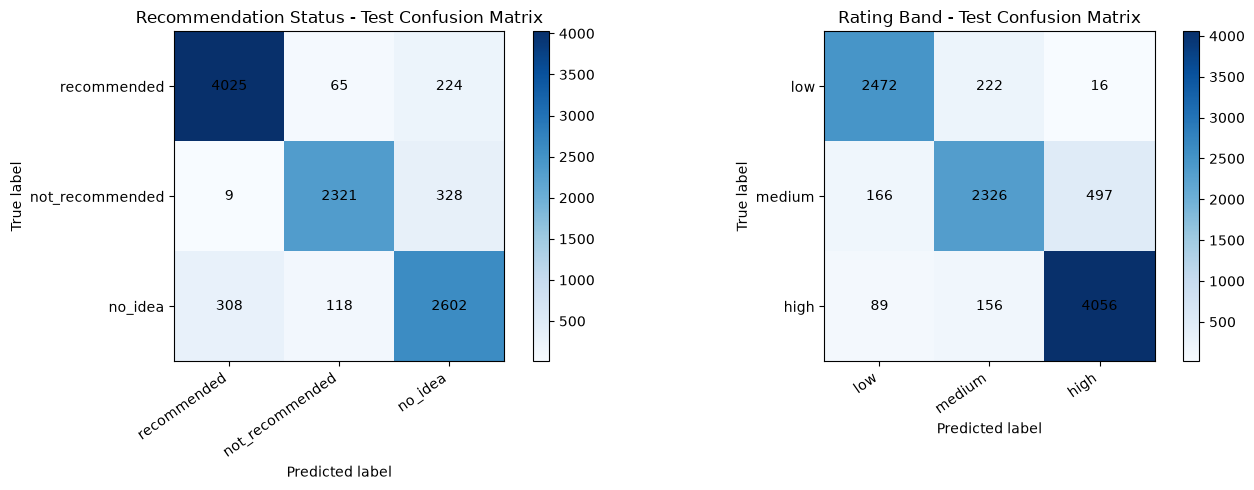

In [40]:
# Display per-class classification reports
print("Recommendation Status - Classification Report")
print(
    classification_report(
        all_recommendation_labels,
        all_recommendation_predictions,
        labels=list(range(len(RECOMMENDATION_LABELS))),
        target_names=RECOMMENDATION_LABELS,
        zero_division=0
    )
)

print("Rating Band - Classification Report")
print(
    classification_report(
        all_rating_labels,
        all_rating_predictions,
        labels=list(range(len(RATING_LABELS))),
        target_names=RATING_LABELS,
        zero_division=0
    )
)

# Plot confusion matrices
recommendation_cm = confusion_matrix(
    all_recommendation_labels,
    all_recommendation_predictions,
    labels=list(range(len(RECOMMENDATION_LABELS)))
)

rating_cm = confusion_matrix(
    all_rating_labels,
    all_rating_predictions,
    labels=list(range(len(RATING_LABELS)))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, labels, title in [
    (axes[0], recommendation_cm, RECOMMENDATION_LABELS, "Recommendation Status"),
    (axes[1], rating_cm, RATING_LABELS, "Rating Band")
]:
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(f"{title} - Test Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticklabels(labels)

    # Write the number of samples inside each cell
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            ax.text(col, row, str(cm[row, col]), ha="center", va="center")

    fig.colorbar(image, ax=ax)

plt.tight_layout()
plt.show()


### Evaluation on Real Test Set

In [28]:
# ============================================================
# 1. Define the new test file path
# ============================================================

NEW_TEST_PATH = Path("../data/test_10k_corrected.csv")

if not NEW_TEST_PATH.exists():
    raise FileNotFoundError(
        f"New test dataset not found: {NEW_TEST_PATH.resolve()}"
    )

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_CHECKPOINT_PATH}"
    )


# ============================================================
# 2. Load and prepare the new test dataset
# ============================================================

new_test_df = pd.read_csv(NEW_TEST_PATH)

# Standardize column names using the previously defined function
new_test_df = standardize_columns(new_test_df)

# Check required columns
required_columns = [
    TEXT_COL,
    RECOMMENDATION_COL
]

missing_columns = [
    col for col in required_columns
    if col not in new_test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Apply the same preprocessing used for the original datasets
new_test_df = prepare_dataframe(
    new_test_df,
    "New Test"
)

print("\nNew test dataset loaded successfully.")
print("Dataset shape:", new_test_df.shape)


# ============================================================
# 3. Create a new Dataset and DataLoader
# ============================================================

new_test_dataset = ReviewDataset(new_test_df)

new_test_loader = DataLoader(
    new_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("New test DataLoader created successfully.")
print("Number of samples:", len(new_test_dataset))
print("Number of batches:", len(new_test_loader))


# ============================================================
# 4. Load the best checkpoint
# ============================================================

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(DEVICE)

print("\nLoaded best checkpoint from epoch:", best_checkpoint["epoch"])
print("Best validation score:", f"{best_checkpoint['best_val_score']:.4f}")

# Set the model to evaluation mode
model.eval()


# ============================================================
# 5. Evaluate the new test dataset
# ============================================================

all_recommendation_labels = []
all_recommendation_predictions = []

all_rating_labels = []
all_rating_predictions = []

test_total_loss = 0.0
test_total_batches = 0

with torch.no_grad():

    for batch in tqdm(new_test_loader, desc="Evaluating New Test Set"):

        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        recommendation_labels = batch["recommendation_labels"].to(DEVICE)
        rating_labels = batch["rating_labels"].to(DEVICE)

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate loss on available labels
        loss, _, _ = compute_multitask_loss(
            outputs,
            recommendation_labels,
            rating_labels
        )

        if loss is not None:
            test_total_loss += loss.item()
            test_total_batches += 1

        # Recommendation task: ignore samples without valid labels
        recommendation_mask = recommendation_labels != -100

        if recommendation_mask.any():

            recommendation_predictions = torch.argmax(
                outputs["recommendation_logits"][recommendation_mask],
                dim=1
            )

            all_recommendation_labels.extend(
                recommendation_labels[recommendation_mask].cpu().tolist()
            )

            all_recommendation_predictions.extend(
                recommendation_predictions.cpu().tolist()
            )

        # Rating task: ignore samples without valid labels
        rating_mask = rating_labels != -100

        if rating_mask.any():

            rating_predictions = torch.argmax(
                outputs["rating_logits"][rating_mask],
                dim=1
            )

            all_rating_labels.extend(
                rating_labels[rating_mask].cpu().tolist()
            )

            all_rating_predictions.extend(
                rating_predictions.cpu().tolist()
            )


# ============================================================
# 6. Calculate evaluation metrics
# ============================================================

test_loss = (
    test_total_loss / test_total_batches
    if test_total_batches > 0 else np.nan
)

from sklearn.metrics import precision_score, recall_score


def calculate_test_metrics(true_labels, predictions):

    if len(true_labels) == 0:
        return {
            "Accuracy": np.nan,
            "Precision (Macro)": np.nan,
            "Recall (Macro)": np.nan,
            "F1 (Macro)": np.nan,
            "F1 (Weighted)": np.nan
        }

    return {
        "Accuracy": accuracy_score(true_labels, predictions),

        "Precision (Macro)": precision_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Recall (Macro)": recall_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "F1 (Macro)": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "F1 (Weighted)": f1_score(
            true_labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    }


recommendation_metrics = calculate_test_metrics(
    all_recommendation_labels,
    all_recommendation_predictions
)

rating_metrics = calculate_test_metrics(
    all_rating_labels,
    all_rating_predictions
)


# ============================================================
# 7. Display final test results
# ============================================================

test_results_df = pd.DataFrame(
    [recommendation_metrics, rating_metrics],
    index=[
        "Recommendation Status",
        "Rating Band"
    ]
)

print("\n" + "=" * 50)
print("NEW TEST DATASET EVALUATION RESULTS")
print("=" * 50)

print(f"\nTest Loss: {test_loss:.4f}")

print(
    "Number of labeled recommendation samples:",
    len(all_recommendation_labels)
)

print(
    "Number of labeled rating samples:",
    len(all_rating_labels)
)

print(
    "Number of unlabeled recommendation samples:",
    len(new_test_dataset) - len(all_recommendation_labels)
)

display(test_results_df.round(4))

New Test prepared: (10000, 6)

New test dataset loaded successfully.
Dataset shape: (10000, 6)
New test DataLoader created successfully.
Number of samples: 10000
Number of batches: 1250

Loaded best checkpoint from epoch: 2
Best validation score: 0.7145


Evaluating New Test Set: 100%|██████████| 1250/1250 [14:35<00:00,  1.43it/s]


NEW TEST DATASET EVALUATION RESULTS

Test Loss: 0.4946
Number of labeled recommendation samples: 10000
Number of labeled rating samples: 10000
Number of unlabeled recommendation samples: 0


,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted)
Recommendation Status,0.8013,0.8084,0.8002,0.8016,0.8052
Rating Band,0.7975,0.7942,0.7916,0.7920,0.7966


### Detailed Test Classification Reports

Recommendation Status - Classification Report
                 precision    recall  f1-score   support

    recommended       0.93      0.82      0.87      3369
not_recommended       0.84      0.81      0.83      3600
        no_idea       0.66      0.77      0.71      3031

       accuracy                           0.80     10000
      macro avg       0.81      0.80      0.80     10000
   weighted avg       0.81      0.80      0.81     10000

Rating Band - Classification Report
              precision    recall  f1-score   support

         low       0.79      0.86      0.83      3586
      medium       0.69      0.66      0.68      3045
        high       0.89      0.85      0.87      3369

    accuracy                           0.80     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.80      0.80      0.80     10000



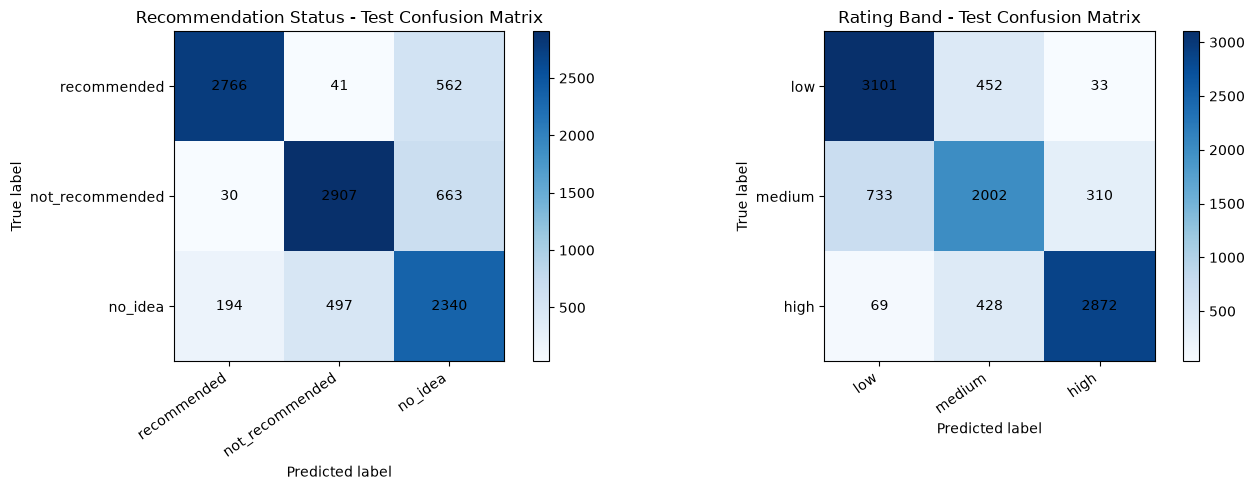

In [29]:
# Display per-class classification reports
print("Recommendation Status - Classification Report")
print(
    classification_report(
        all_recommendation_labels,
        all_recommendation_predictions,
        labels=list(range(len(RECOMMENDATION_LABELS))),
        target_names=RECOMMENDATION_LABELS,
        zero_division=0
    )
)

print("Rating Band - Classification Report")
print(
    classification_report(
        all_rating_labels,
        all_rating_predictions,
        labels=list(range(len(RATING_LABELS))),
        target_names=RATING_LABELS,
        zero_division=0
    )
)

# Plot confusion matrices
recommendation_cm = confusion_matrix(
    all_recommendation_labels,
    all_recommendation_predictions,
    labels=list(range(len(RECOMMENDATION_LABELS)))
)

rating_cm = confusion_matrix(
    all_rating_labels,
    all_rating_predictions,
    labels=list(range(len(RATING_LABELS)))
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, labels, title in [
    (axes[0], recommendation_cm, RECOMMENDATION_LABELS, "Recommendation Status"),
    (axes[1], rating_cm, RATING_LABELS, "Rating Band")
]:
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(f"{title} - Test Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticklabels(labels)

    # Write the number of samples inside each cell
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            ax.text(col, row, str(cm[row, col]), ha="center", va="center")

    fig.colorbar(image, ax=ax)

plt.tight_layout()
plt.show()


## Examining Incorrect Predictions on Both Test Sets

In this section, we inspect a few incorrectly predicted examples from **both test datasets**:

1. Artificial Test Set (`test_df`)
2. Real Test Set (`new_test_df`)

For each test set, we examine mistakes made by both classification heads:

- Recommendation Status
- Rating Band

Samples with missing labels (`-100`) are excluded. The examples show the review text, the true label, and the predicted label.

In [ ]:
# Number of incorrect examples to display for each task and test set
N_WRONG_EXAMPLES = 15


def inspect_wrong_predictions(dataframe, dataset_name, model, n=5):
    """
    Find and display incorrectly predicted examples for both tasks.

    Each row in the output contains:
    - Review text
    - True label
    - Predicted label
    """

    # Create a DataLoader without shuffling so predictions remain
    # in the same order as the original dataframe.
    dataset = ReviewDataset(dataframe)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=0
    )

    # Store predictions for the two classification tasks
    recommendation_predictions = []
    rating_predictions = []

    model.eval()

    with torch.no_grad():

        for batch in tqdm(loader, desc=f"Finding errors: {dataset_name}"):

            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Convert model outputs to predicted class IDs
            recommendation_batch_predictions = torch.argmax(
                outputs["recommendation_logits"],
                dim=1
            ).cpu().tolist()

            rating_batch_predictions = torch.argmax(
                outputs["rating_logits"],
                dim=1
            ).cpu().tolist()

            recommendation_predictions.extend(
                recommendation_batch_predictions
            )
            rating_predictions.extend(
                rating_batch_predictions
            )

    # Convert true labels to numerical IDs using the same mappings
    true_recommendation = [
        recommendation_to_id.get(label, -100)
        for label in dataframe[RECOMMENDATION_COL]
    ]

    if RATING_BAND_COL in dataframe.columns:
        rating_values = dataframe[RATING_BAND_COL].astype("string").tolist()

        true_rating = [
            rating_to_id.get(label, -100) if pd.notna(label) else -100
            for label in rating_values
        ]
    else:
        true_rating = [-100] * len(dataframe)

    # Prepare readable ID-to-label mappings
    recommendation_id_to_label = {
        index: label
        for label, index in recommendation_to_id.items()
    }

    rating_id_to_label = {
        index: label
        for label, index in rating_to_id.items()
    }

    # ------------------------------------------------------------
    # 1. Incorrect Recommendation Status predictions
    # ------------------------------------------------------------

    wrong_recommendation_indices = [
        index
        for index, (true_label, predicted_label) in enumerate(
            zip(true_recommendation, recommendation_predictions)
        )
        if true_label != -100 and true_label != predicted_label
    ]

    print("\\n" + "=" * 70)
    print(f"{dataset_name} - Incorrect Recommendation Status Predictions")
    print("=" * 70)
    print("Total incorrect predictions:", len(wrong_recommendation_indices))

    if wrong_recommendation_indices:

        selected_indices = wrong_recommendation_indices[:n]

        recommendation_errors = pd.DataFrame({
            "Review Text": [
                dataframe.iloc[index][TEXT_COL]
                for index in selected_indices
            ],
            "True Label": [
                recommendation_id_to_label[true_recommendation[index]]
                for index in selected_indices
            ],
            "Predicted Label": [
                recommendation_id_to_label[
                    recommendation_predictions[index]
                ]
                for index in selected_indices
            ]
        })

        display(recommendation_errors)

    else:
        print("No incorrect predictions were found for this task.")

    # ------------------------------------------------------------
    # 2. Incorrect Rating Band predictions
    # ------------------------------------------------------------

    wrong_rating_indices = [
        index
        for index, (true_label, predicted_label) in enumerate(
            zip(true_rating, rating_predictions)
        )
        if true_label != -100 and true_label != predicted_label
    ]

    print("\\n" + "=" * 70)
    print(f"{dataset_name} - Incorrect Rating Band Predictions")
    print("=" * 70)
    print("Total incorrect predictions:", len(wrong_rating_indices))

    if wrong_rating_indices:

        selected_indices = wrong_rating_indices[:n]

        rating_errors = pd.DataFrame({
            "Review Text": [
                dataframe.iloc[index][TEXT_COL]
                for index in selected_indices
            ],
            "True Label": [
                rating_id_to_label[true_rating[index]]
                for index in selected_indices
            ],
            "Predicted Label": [
                rating_id_to_label[rating_predictions[index]]
                for index in selected_indices
            ]
        })

        display(rating_errors)

    else:
        print("No incorrect predictions were found for this task.")


# Inspect errors on the artificial test set
inspect_wrong_predictions(
    dataframe=test_df,
    dataset_name="Artificial Test Set",
    model=model,
    n=N_WRONG_EXAMPLES
)

Finding errors: Artificial Test Set:   0%|          | 0/1250 [00:00<?, ?it/s]

Finding errors: Artificial Test Set: 100%|██████████| 1250/1250 [16:37<00:00,  1.25it/s]

\n======================================================================
Artificial Test Set - Incorrect Recommendation Status Predictions
Total incorrect predictions: 7636


,Review Text,True Label,Predicted Label
0,راحته و تو گوش نمیمونه ولی بعد از یه ساعت گوشم...,no_idea,not_recommended
1,خدا خیرتون بده. تو روز شگفت‌انگیز گرفتم. تاچ‌پ...,not_recommended,no_idea
2,دقيقا نميدونم، معمولي,no_idea,recommended
3,شستنش راحته ولی دسته‌ش شل شد..,no_idea,not_recommended
4,SSD سرعتش محشره!!,recommended,not_recommended
5,همه تعریف کردن. جنسش عالیه و خیلی نرمه. فروشند...,recommended,no_idea
6,دو ماهه دارم استفاده میکنم، ست ابزار، برای کار...,no_idea,not_recommended
7,تو فروشگاه دیده بودم و از دیجی‌کالا خریدم و بس...,recommended,not_recommended
8,باسلام و احترام بوی خیلی خوبی داره سپاس از زحم...,recommended,no_idea
9,سومین باره از این برند میخرم. تازه بود. همه خو...,recommended,not_recommended


\n======================================================================
Artificial Test Set - Incorrect Rating Band Predictions
Total incorrect predictions: 5378


,Review Text,True Label,Predicted Label
0,چای، کیفیتش افت کرده، خیلی گرون‌تر از بیرونه.,low,medium
1,راحته و تو گوش نمیمونه ولی بعد از یه ساعت گوشم...,medium,high
2,خدا خیرتون بده. تو روز شگفت‌انگیز گرفتم. تاچ‌پ...,low,high
3,شستنش راحته ولی دسته‌ش شل شد..,medium,high
4,SSD سرعتش محشره!!,high,medium
5,دو ماهه دارم استفاده میکنم، ست ابزار، برای کار...,medium,high
6,بعد از کلی تحقیق گرفتم، کفش، دوامش خوبه، برای ...,high,medium
7,باسلام و احترام، کابل، قطعه‌هاش ناقص بود، گرم ...,low,high
8,واقعا آموزنده‌ست. توصیه میکنم حتما بخونید. خیل...,high,low
9,با اینکه اپلیکیشنش مدام ارور میده، بند نرمی دا...,medium,high


NameError: name 'new_test_df' is not defined

In [38]:

# ============================================================
# 2. Load and prepare the new test dataset
# ============================================================
NEW_TEST_PATH = "../data/test_10k_corrected.csv"

new_test_df = pd.read_csv(NEW_TEST_PATH)

# Standardize column names using the previously defined function
new_test_df = standardize_columns(new_test_df)

# Check required columns
required_columns = [
    TEXT_COL,
    RECOMMENDATION_COL
]

missing_columns = [
    col for col in required_columns
    if col not in new_test_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Apply the same preprocessing used for the original datasets
new_test_df = prepare_dataframe(
    new_test_df,
    "New Test"
)

print("\nNew test dataset loaded successfully.")
print("Dataset shape:", new_test_df.shape)


# ============================================================
# 3. Create a new Dataset and DataLoader
# ============================================================

new_test_dataset = ReviewDataset(new_test_df)

new_test_loader = DataLoader(
    new_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("New test DataLoader created successfully.")
print("Number of samples:", len(new_test_dataset))
print("Number of batches:", len(new_test_loader))


# Inspect errors on the real test set
inspect_wrong_predictions(
    dataframe=new_test_df,
    dataset_name="Real Test Set",
    model=model,
    n=N_WRONG_EXAMPLES
)

New Test prepared: (10000, 6)

New test dataset loaded successfully.
Dataset shape: (10000, 6)
New test DataLoader created successfully.
Number of samples: 10000
Number of batches: 1250


Finding errors: Real Test Set: 100%|██████████| 1250/1250 [26:13<00:00,  1.26s/it]

\n======================================================================
Real Test Set - Incorrect Recommendation Status Predictions
Total incorrect predictions: 6823


,Review Text,True Label,Predicted Label
0,کیفیت معمولی و نیازمند استفاده از بهبود دهنده,no_idea,recommended
1,طراحی زیبا و جنس خوبی داشت اما قیمتش یه کم بال...,recommended,not_recommended
2,خوبه این رنگ رو چون کم داشتم تک خریدمش,recommended,not_recommended
3,صابون اشتباه ارسال شد بجای آووکادو آلوئه ورا ا...,not_recommended,no_idea
4,ضخامتش صدای خیلی زیرتری نسبت به ناخن داره,no_idea,not_recommended
5,من فکر نمیکردم سایزش کوچیک باشه ولی در کل خوب بود,no_idea,not_recommended
6,برای لثه های حساس بسیار مناسب است و به توصیه د...,recommended,no_idea
7,خرید از این فروشنده رو توصیه میکنم کاملا مثل ع...,recommended,not_recommended
8,نازک تر از این بود که بشه بهش گفت طبی ولی در ک...,no_idea,not_recommended
9,بوی لباس شسته شده و تمیز رو میده یا بقول دوستا...,recommended,not_recommended


\n======================================================================
Real Test Set - Incorrect Rating Band Predictions
Total incorrect predictions: 6638


,Review Text,True Label,Predicted Label
0,چیزی ک تو عکس دیدم تا چیزی ک بدستم رسید اصلآ ی...,low,high
1,جنس کاعذ را جدیدا از نوع بالکی یا کاهی بکار می...,low,high
2,فکر می کردم ساخت آلمان باشه ولی مداد فیک هست و...,low,medium
3,بسیار ناز و بی کیفیت قیمت بالا سایز کوچکتر از ...,low,medium
4,اندازه عروسک تحویلی با توی سایت فرق داشت 20 سا...,low,high
5,صابون اشتباه ارسال شد بجای آووکادو آلوئه ورا ا...,low,high
6,ضخامتش صدای خیلی زیرتری نسبت به ناخن داره,medium,high
7,قبلا کیفت بهتری داشت,low,medium
8,پلاستیک خالص جنس خیلی بدی داره سایز لارج سفارش...,low,high
9,از نظر ظاهر خیلی بی کیفیت مخصوصا کاغذش و جلدش ...,low,high


In [9]:

import json
from pathlib import Path
# Initialize the multi-task model

model = MultiTaskParsBERT(
    model_name=MODEL_NAME,
    num_recommendation_classes=len(RECOMMENDATION_LABELS),
    num_rating_classes=len(RATING_LABELS),
    dropout_rate=0.3
)

# Move the model to the selected device
model = model.to(DEVICE)

CHECKPOINT_DIR = Path("../checkpoint")
BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "parsbert_multitask_best.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the Transformer artifact directory
ARTIFACT_DIR = Path("../artifacts/transformer")

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Load the best checkpoint
best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Restore the best model weights
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# Set the model to evaluation mode
model.to(DEVICE)
model.eval()

# Save only the model weights
MODEL_PATH = ARTIFACT_DIR / "model_state_dict.pt"

torch.save(
    model.state_dict(),
    MODEL_PATH
)

# Save the tokenizer
TOKENIZER_DIR = ARTIFACT_DIR / "tokenizer"

tokenizer.save_pretrained(TOKENIZER_DIR)

# Save model metadata
metadata = {
    "model_name": MODEL_NAME,
    "model_type": "MultiTaskParsBERT",
    "max_length": MAX_LENGTH,
    "dropout_rate": 0.3,

    "recommendation_labels": RECOMMENDATION_LABELS,
    "rating_labels": RATING_LABELS,

    "best_epoch": best_checkpoint["epoch"],
    "best_validation_score": best_checkpoint["best_val_score"]
}

METADATA_PATH = ARTIFACT_DIR / "metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(
        metadata,
        file,
        ensure_ascii=False,
        indent=4
    )

print("Transformer artifacts saved successfully!")

print("\nSaved files:")
print(MODEL_PATH)
print(TOKENIZER_DIR)
print(METADATA_PATH)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3523.58it/s]
[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transformer artifacts saved successfully!

Saved files:
..\artifacts\transformer\model_state_dict.pt
..\artifacts\transformer\tokenizer
..\artifacts\transformer\metadata.json
